**PRACTICAL LECTURE 3**

**PART1. Autoencoders**

**2025-2026**

1. Import libraries

In [31]:
import torch
import torchvision
from torch import nn
from torch.utils.data import DataLoader
from torchvision import transforms
from torchvision.datasets import MNIST
from matplotlib import pyplot as plt
import numpy as np

2. Convert vector to image
The following function allows to convert a vector to an image

In [32]:
def to_img(x):
    x = 0.5 * (x + 1)
    x = x.view(x.size(0), 28, 28)
    return x

3. We now write a function which allows to display the images using the imshow() function.

In [33]:
def display_images(in_, out, n=1):
    for N in range(n):
        if in_ is not None:
            in_pic = to_img(in_.cpu().data)
            plt.figure(figsize=(18, 6))
            for i in range(4):
                plt.subplot(1,4,i+1)
                plt.imshow(in_pic[i+4*N])
                plt.axis('off')
        out_pic = to_img(out.cpu().data)
        plt.figure(figsize=(18, 6))
        for i in range(4):
            plt.subplot(1,4,i+1)
            plt.imshow(out_pic[i+4*N])
            plt.axis('off')

4. Define a data loading step and load the MNIST dataset (train and test sets).

In [34]:
batch_size = 256

img_transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize((0.5,), (0.5,))
])

dataset = MNIST('./data', transform=img_transform, download=True)
dataloader = DataLoader(dataset, batch_size=batch_size, shuffle=True)

test_dataset = MNIST('./data', train=False, transform=img_transform, download=True)
test_dataloader = DataLoader(test_dataset, batch_size=batch_size, shuffle=False)

5. Fix the used device

In [35]:
device = torch.device("cuda:0" if torch.cuda.is_available() else "cpu")

6. Define the Autoencoder model architecture and reconstruction loss
with :
n = 28 x 28 = 784

A. Use d = 30  for standard AE (under-complete hidden layer)

B. Use d = 500 for denoising AE (over-complete hidden layer)

C. Compute **by hand** the number of parameters of the autoencoder for d = 30 and for d = 500, then check your answer with `sum(p.numel() for p in model.parameters())`.

D. Explain the difference between standard AE and denoising AE. Why would an over-complete standard AE (d = 500, no noise) be useless?
Analyse the results and conclude.

In [36]:
d=30

class Autoencoder(nn.Module):
    def __init__(self):
        super().__init__()
        self.encoder = nn.Sequential(
            nn.Linear(28 * 28, d),
            nn.Tanh(),
        )
        self.decoder = nn.Sequential(
            nn.Linear(d, 28 * 28),
            nn.Tanh(),
        )

    def forward(self, x):
        x = self.encoder(x)
        x = self.decoder(x)
        return x

model = Autoencoder().to(device)
criterion = nn.MSELoss()

7. Configure the optimiser. We use here : learning_rate equals to 1e-3

In [37]:
learning_rate = 1e-3

optimizer = torch.optim.Adam(
    model.parameters(),
    lr=learning_rate,
)

8. Train the standard autoencoder and the denoising autoencoder using the following code :

epoch [1/20], loss:0.1946
epoch [2/20], loss:0.1425
epoch [3/20], loss:0.1161
epoch [4/20], loss:0.1055
epoch [5/20], loss:0.0946
epoch [6/20], loss:0.0957
epoch [7/20], loss:0.0890
epoch [8/20], loss:0.0805
epoch [9/20], loss:0.0753
epoch [10/20], loss:0.0749
epoch [11/20], loss:0.0741
epoch [12/20], loss:0.0661
epoch [13/20], loss:0.0738
epoch [14/20], loss:0.0707
epoch [15/20], loss:0.0655
epoch [16/20], loss:0.0589
epoch [17/20], loss:0.0625
epoch [18/20], loss:0.0608
epoch [19/20], loss:0.0598
epoch [20/20], loss:0.0552


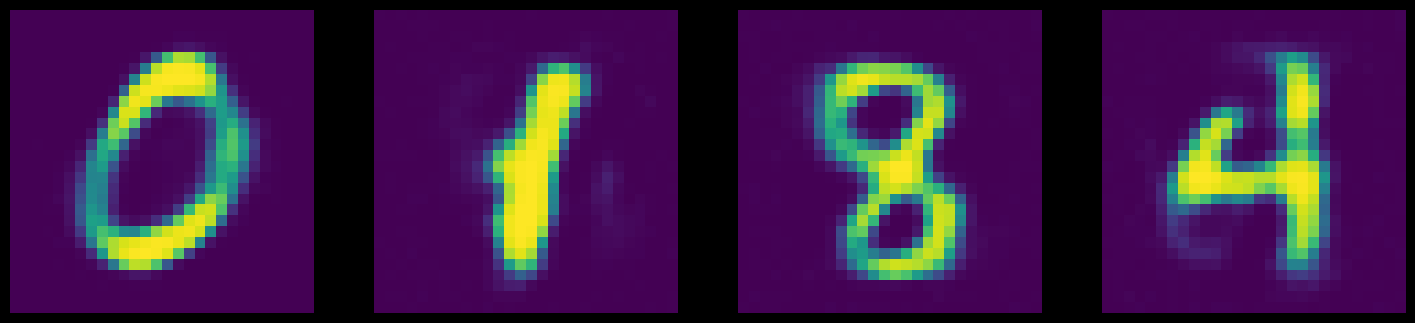

In [38]:
num_epochs = 20
# do = nn.Dropout()  # comment out for standard AE
for epoch in range(num_epochs):
    for data in dataloader:
        img, _ = data
        img = img.to(device)
        img = img.view(img.size(0), -1)
        # noise = do(torch.ones(img.shape)).to(device)
        # img_bad = (img * noise).to(device)  # comment out for standard AE
        # ===================forward=====================
        output = model(img)  # feed <img> (for std AE) or <img_bad> (for denoising AE)
        loss = criterion(output, img.data)
        # ===================backward====================
        optimizer.zero_grad()
        loss.backward()
        optimizer.step()
    # ===================log========================
    print(f'epoch [{epoch + 1}/{num_epochs}], loss:{loss.item():.4f}')
display_images(None, output)  # pass (None, output) for std AE, (img_bad, output) for denoising AE

9. The Dropout noise above sets random pixels to zero. Write a second version of the denoising AE (d = 500) where the noise is **additive Gaussian noise** of standard deviation $\sigma = 0.5$ (be careful to keep the pixel values in $[-1, 1]$). Display noisy inputs and reconstructions, and compare with the Dropout version.

epoch [1/20], loss:0.0483
epoch [2/20], loss:0.0311
epoch [3/20], loss:0.0267
epoch [4/20], loss:0.0247
epoch [5/20], loss:0.0216
epoch [6/20], loss:0.0231
epoch [7/20], loss:0.0213
epoch [8/20], loss:0.0205
epoch [9/20], loss:0.0206
epoch [10/20], loss:0.0223
epoch [11/20], loss:0.0216
epoch [12/20], loss:0.0202
epoch [13/20], loss:0.0197
epoch [14/20], loss:0.0199
epoch [15/20], loss:0.0192
epoch [16/20], loss:0.0194
epoch [17/20], loss:0.0193
epoch [18/20], loss:0.0196
epoch [19/20], loss:0.0195
epoch [20/20], loss:0.0183


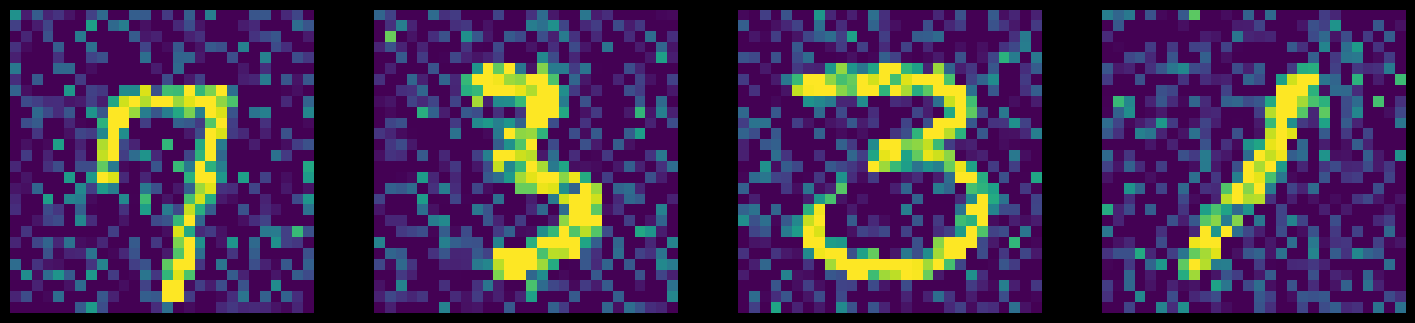

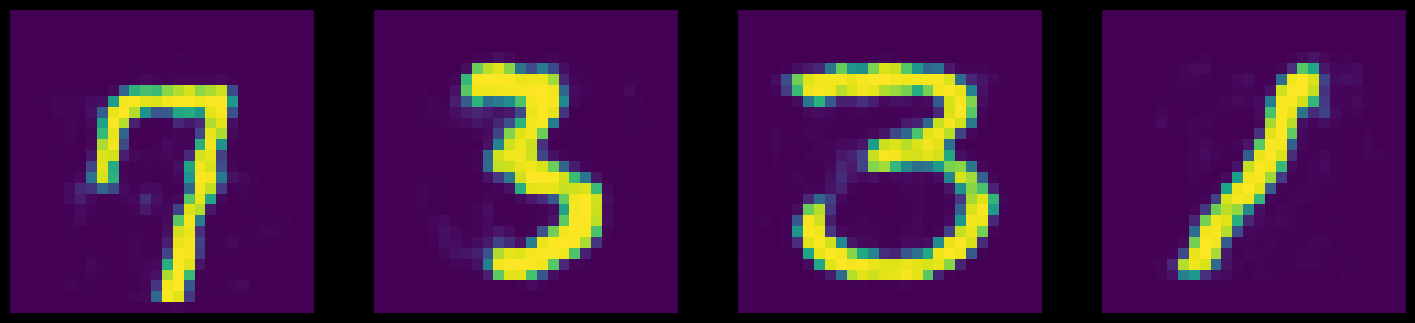

In [39]:
d = 500
model = Autoencoder().to(device)
criterion = nn.MSELoss()
learning_rate = 1e-3

optimizer = torch.optim.Adam(
    model.parameters(),
    lr=learning_rate,
)
num_epochs = 20
# do = nn.Dropout()  # comment out for standard AE
for epoch in range(num_epochs):
    for data in dataloader:
        img, _ = data
        img = img.to(device)
        img = img.view(img.size(0), -1)

        # on remplace bruit dropout par gaussian
        noise = (torch.randn_like(img) * 0.5).to(device)
        # "additif"
        img_bad = img + noise
        # les valeurs de pixels doivent etre comprises entre -1 et 1
        img_bad = torch.clamp(img_bad, min = -1.0, max=1.0)
        
        # ===================forward=====================
        output = model(img_bad)  # feed <img> (for std AE) or <img_bad> (for denoising AE)
        loss = criterion(output, img.data)
        # ===================backward====================
        optimizer.zero_grad()
        loss.backward()
        optimizer.step()
    # ===================log========================
    print(f'epoch [{epoch + 1}/{num_epochs}], loss:{loss.item():.4f}')
display_images(img_bad, output)  # pass (None, output) for std AE, (img_bad, output) for denoising AE

10. Visualise a few kernels of the encoder :

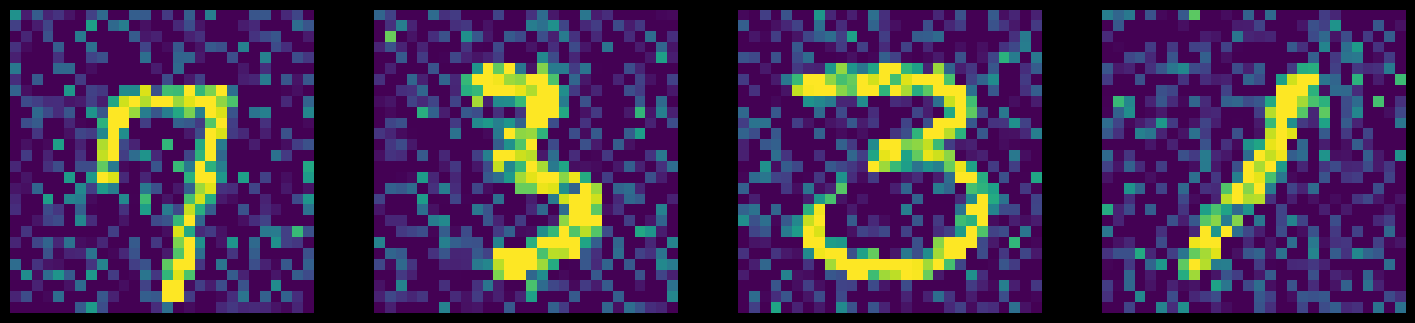

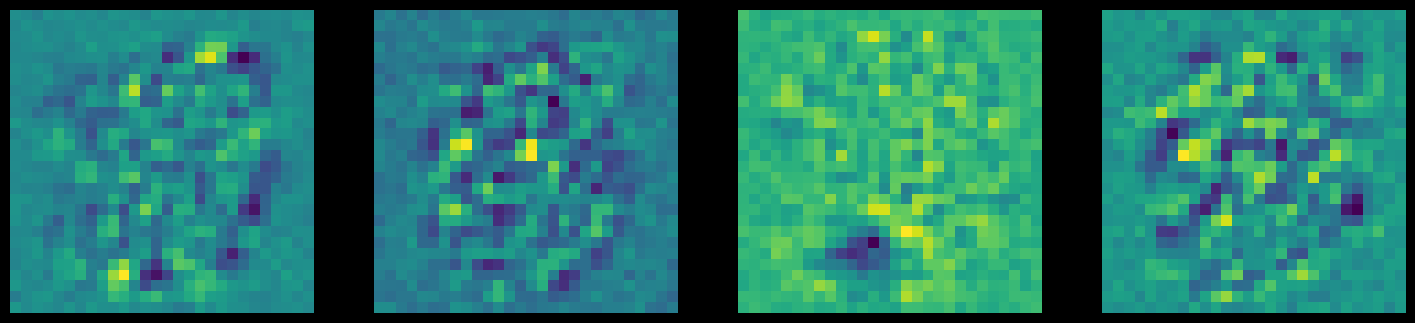

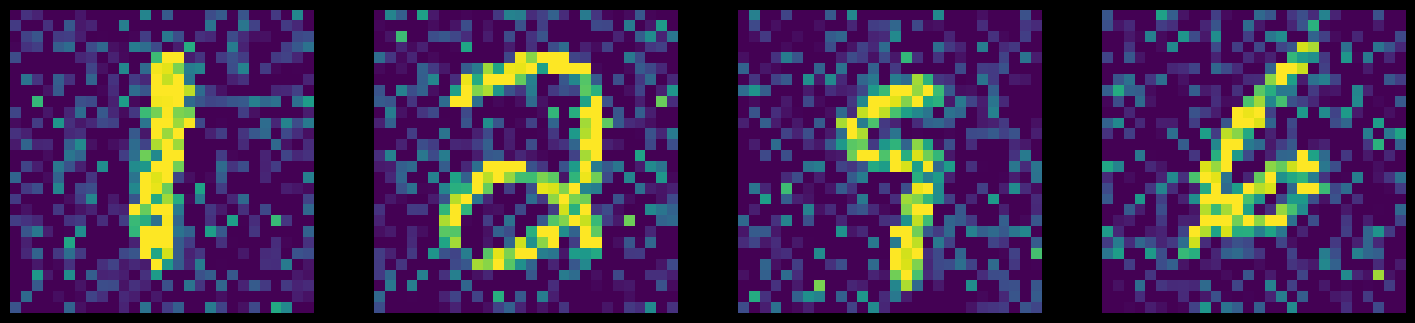

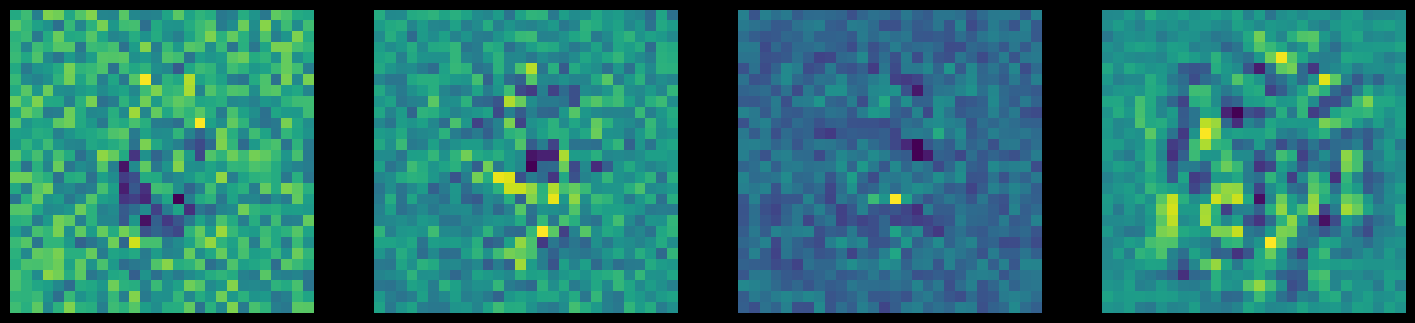

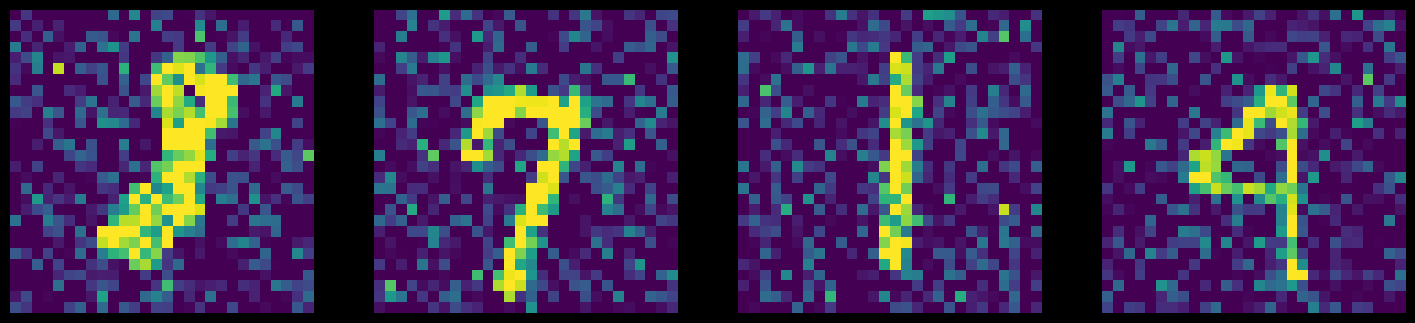

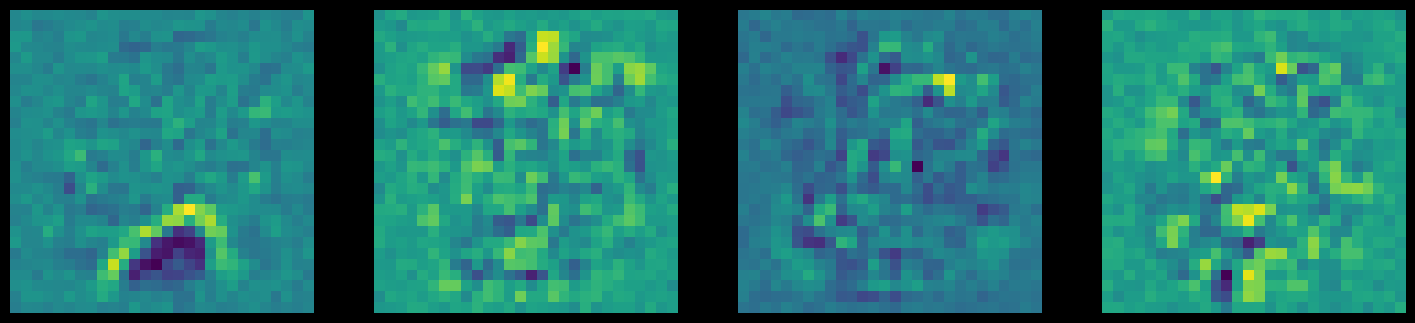

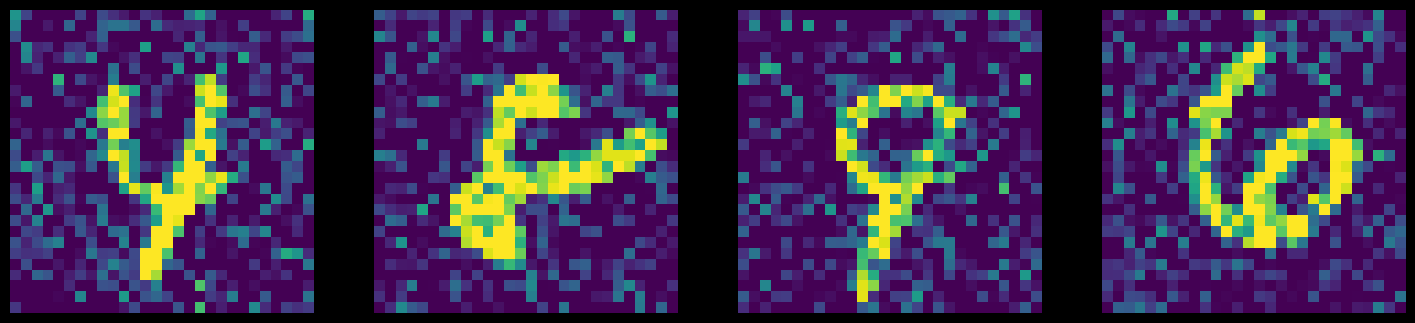

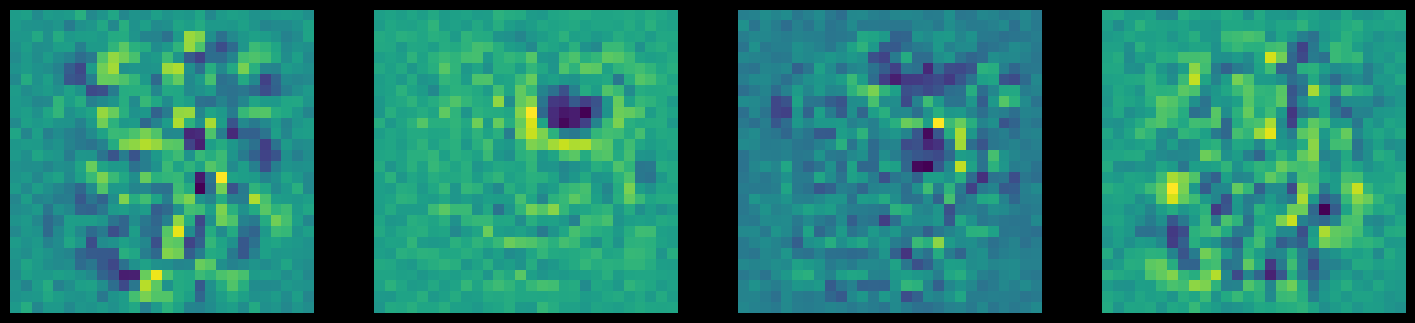

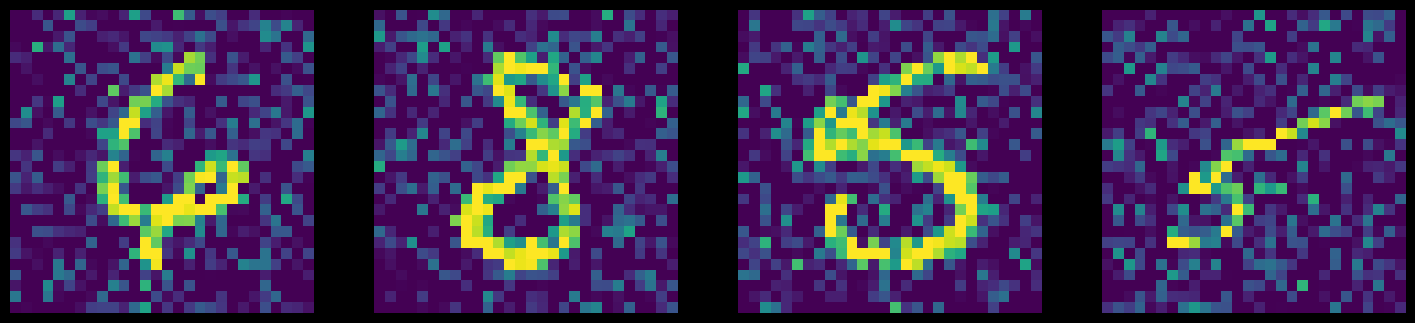

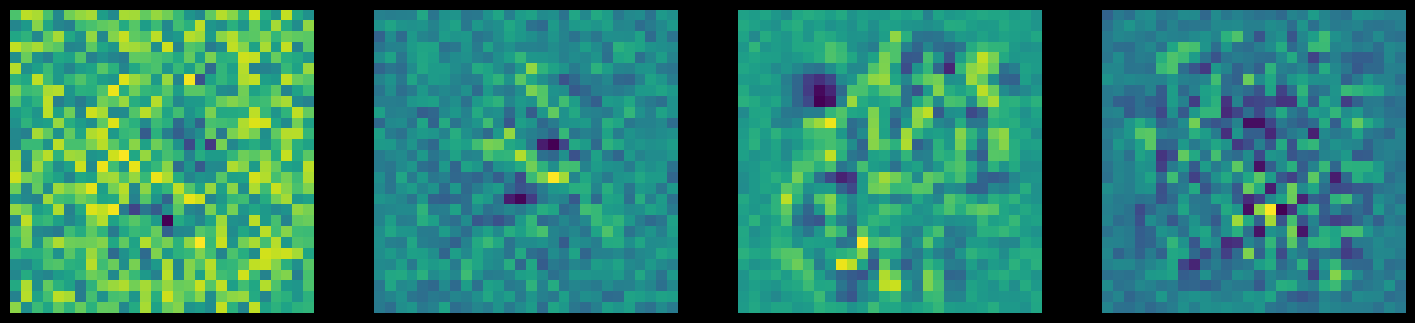

In [40]:
display_images(img_bad, model.encoder[0].weight, 5)

11. Latent space. Train a standard autoencoder with **d = 2** (5 epochs are enough). Encode all the images of the test set and plot the 2-D codes as a scatter plot, with one color per digit (use the labels of `test_dataset`). Which digits are well separated? Which ones overlap? Is this surprising, given that the labels were never used during training?

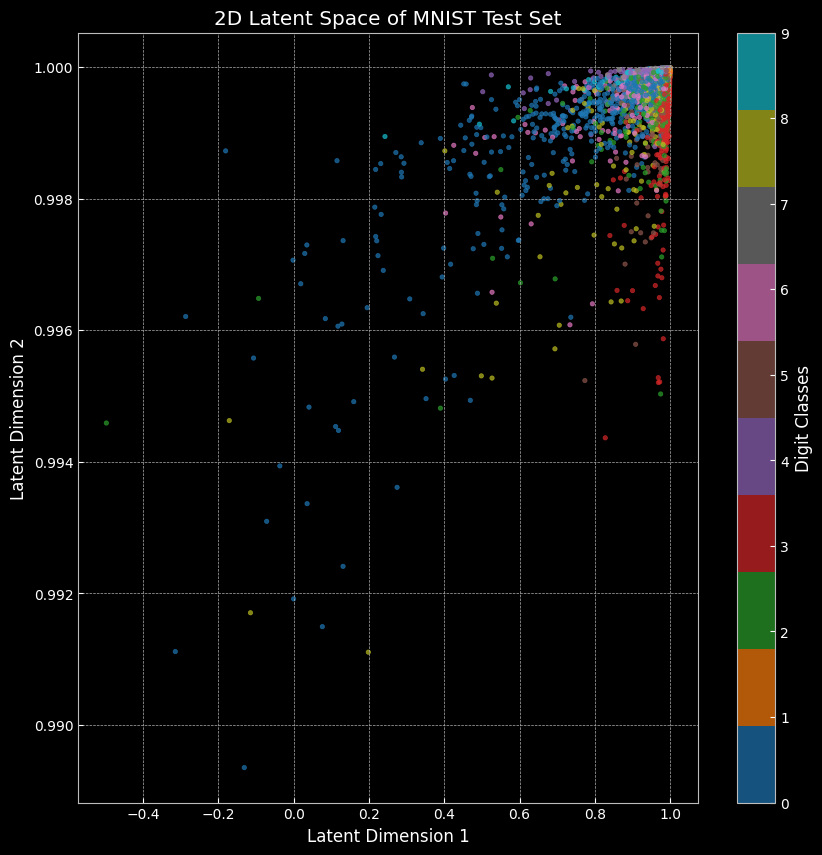

In [41]:
d = 2
model_2d = Autoencoder().to(device)
criterion = nn.MSELoss()
learning_rate = 1e-3

optimizer = torch.optim.Adam(
    model_2d.parameters(),
    lr=learning_rate,
)

num_epochs = 5

model_2d.train()

for epoch in range(num_epochs):
    for data in dataloader:
        img, _ = data
        img = img.to(device)
        img = img.view(img.size(0), -1)
        
        output = model_2d(img)
        loss = criterion(output, img)
        
        optimizer.zero_grad()
        loss.backward()
        optimizer.step()

latent_codes = []
labels_list = []

model_2d.eval()
with torch.no_grad(): # No need to track gradients for evaluation
    for data in test_dataloader:
        img, label = data
        img = img.to(device)
        img = img.view(img.size(0), -1)
        
        code = model_2d.encoder(img)
        latent_codes.append(code)
        labels_list.append(label) 
# on fusuonne les petits lots
latent_codes = torch.cat(latent_codes).numpy()
labels_list = torch.cat(labels_list).numpy()

plt.figure()
scatter = plt.scatter(latent_codes[:, 0], latent_codes[:, 1], c=labels_list, cmap='tab10', alpha=0.7, s=10)
plt.colorbar(scatter, ticks=range(10), label='Digit Classes')
plt.title("2D Latent Space of MNIST Test Set")
plt.xlabel("Latent Dimension 1")
plt.ylabel("Latent Dimension 2")
plt.show()

Réponse question 11 :
- avec d = 2, l’espace latent n'est pas très lisible (c'est très concentrés dans un coin) c'est dû au fait que l’activation tanh de l’encodeur sature (car avec que 2 neurones les poids grandissent et les sorties collent aux bornes [-1,+1])
- chiffre bien séparé : le 0 s'étale loin des autres classes
- chiffres qui se chevauchent : toutes les autres classes sont mélangées dans le coin saturé
- c'est pas surprenant car l’autoencodeur n’utilise jamais les labels, mais pour reconstruire les images il doit placer proches les images qui se ressemblent en pixels et les images d’un même chiffre se ressemblent plus entre elles qu’avec les autres mais 2 dimensions sont trop peu pour séparer 10 classes, et la saturation du tanh écrase une grande partie des points

12. Write a function `test_mse(model)` returning the mean reconstruction error on the **test set**. Train a standard AE (5 epochs each) for d ∈ {2, 10, 30, 100} and plot the test MSE as a function of d. Comment the curve.

dim 2 : epoch [1/5], loss:0.5169
dim 2 : epoch [2/5], loss:0.3333
dim 2 : epoch [3/5], loss:0.2944
dim 2 : epoch [4/5], loss:0.2835
dim 2 : epoch [5/5], loss:0.2673
dim 10 : epoch [1/5], loss:0.2885
dim 10 : epoch [2/5], loss:0.2636
dim 10 : epoch [3/5], loss:0.2263
dim 10 : epoch [4/5], loss:0.2042
dim 10 : epoch [5/5], loss:0.1897
dim 30 : epoch [1/5], loss:0.2094
dim 30 : epoch [2/5], loss:0.1460
dim 30 : epoch [3/5], loss:0.1257
dim 30 : epoch [4/5], loss:0.0924
dim 30 : epoch [5/5], loss:0.0972
dim 100 : epoch [1/5], loss:0.1066
dim 100 : epoch [2/5], loss:0.0698
dim 100 : epoch [3/5], loss:0.0512
dim 100 : epoch [4/5], loss:0.0404
dim 100 : epoch [5/5], loss:0.0335


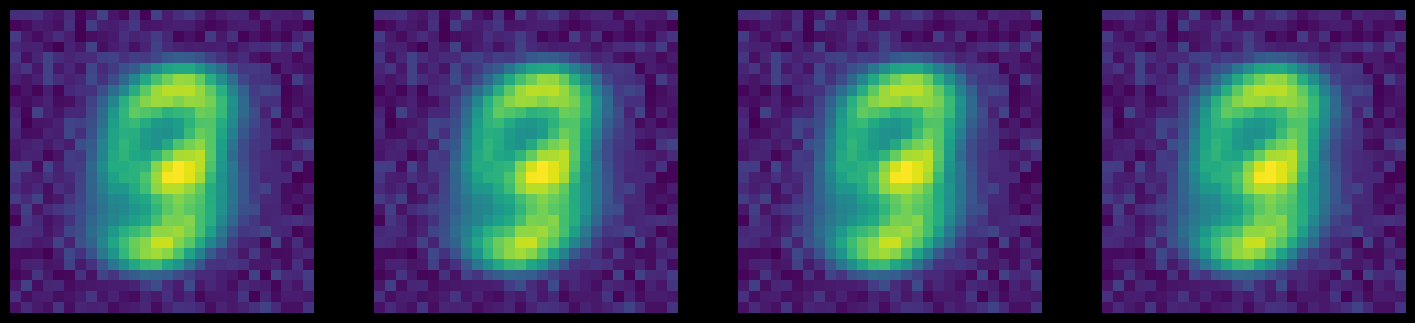

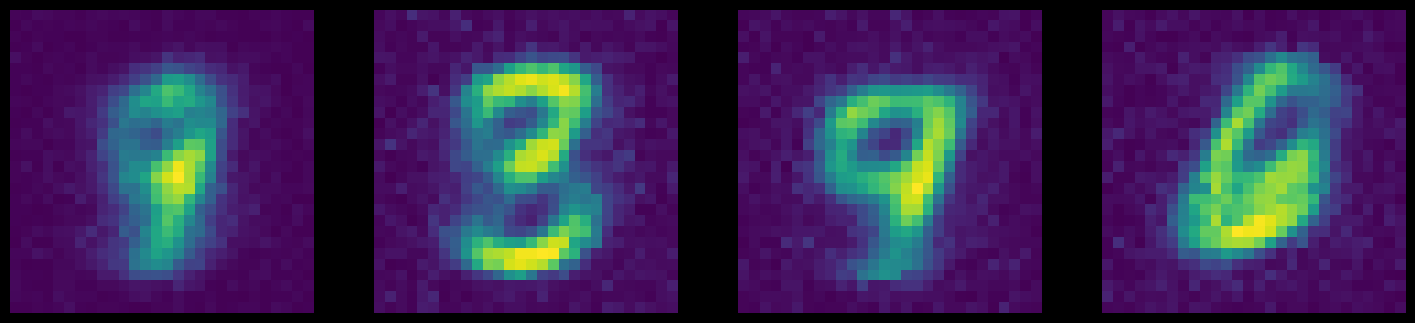

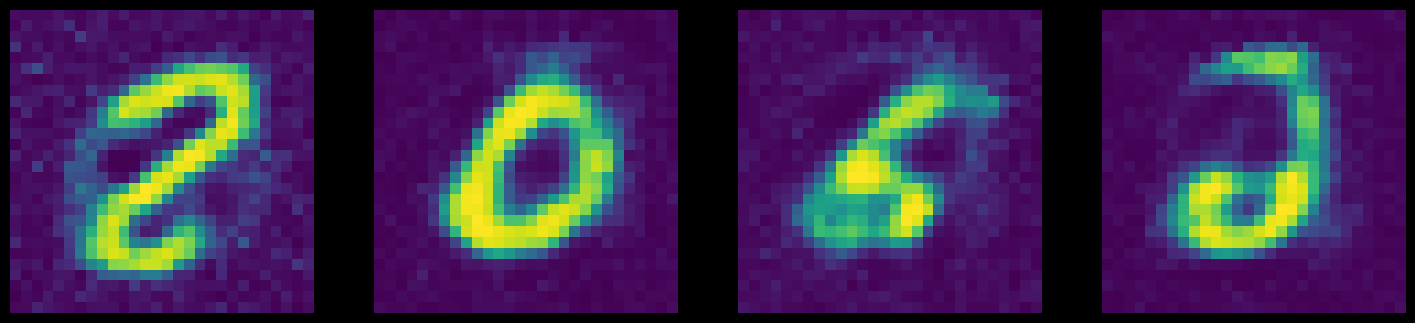

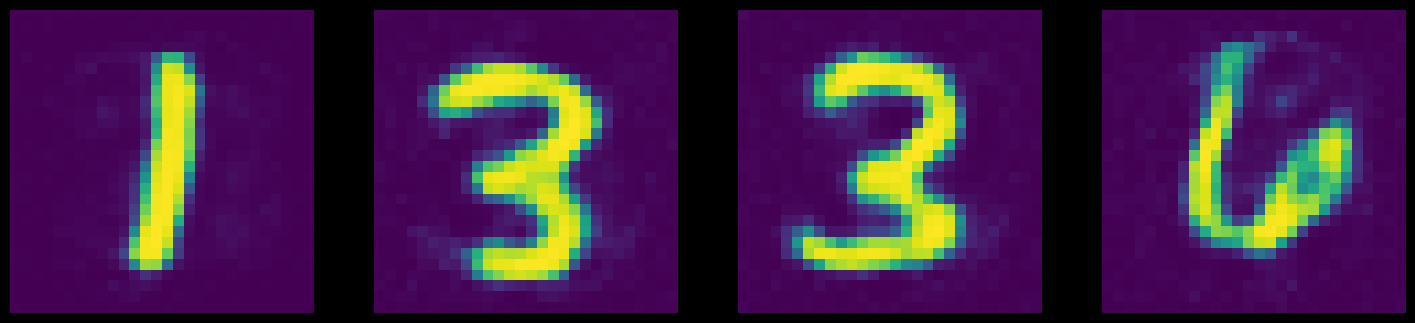

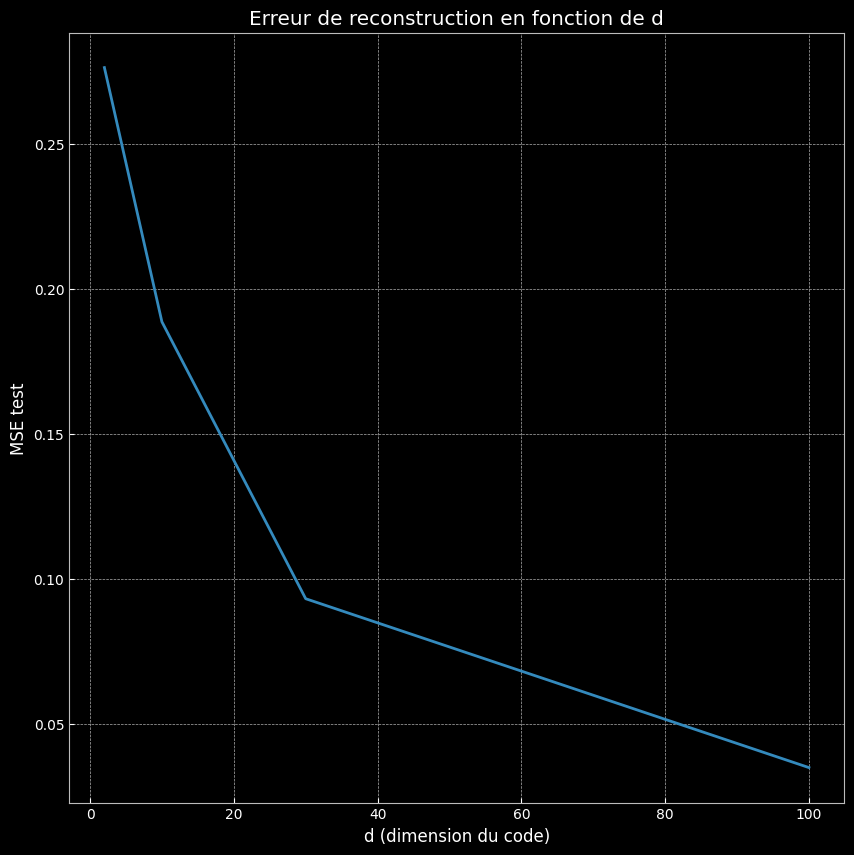

In [42]:
def test_mse(model):
    model.eval()
    total = 0
    n = 0

    with torch.no_grad():
        for data in test_dataloader:
            img, _ = data
            img = img.to(device)
            img = img.view(img.size(0), -1)

            output = model(img)
            dist_carre = (output - img) ** 2
            total = total + (dist_carre).sum().item()
            
            n += img.shape[0] * img.shape[1]
    return total / n

liste_mse_model = []

dim_liste = [2, 10, 30, 100]

for d_valeur in dim_liste :

    d = d_valeur
    model_2d = Autoencoder().to(device)
    criterion = nn.MSELoss()
    learning_rate = 1e-3

    optimizer = torch.optim.Adam(
        model_2d.parameters(),
        lr=learning_rate,
    )

    num_epochs = 5
    for epoch in range(num_epochs):
        for data in dataloader:
            img, _ = data
            img = img.to(device)
            img = img.view(img.size(0), -1)

            output = model_2d(img)
            loss = criterion(output, img.data)
            optimizer.zero_grad()
            loss.backward()
            optimizer.step()
        print(f'dim {d} : epoch [{epoch + 1}/{num_epochs}], loss:{loss.item():.4f}')
    display_images(None, output)

    liste_mse_model.append(test_mse(model_2d))

plt.figure()
plt.plot(dim_liste, liste_mse_model)
plt.xlabel("d (dimension du code)")
plt.ylabel("MSE test")
plt.title("Erreur de reconstruction en fonction de d")
plt.show()

13. Analyse the obtained results.

- plus les dimensions montent plus la MSE baisse, elle est maximale à d=2 ce qui est logique car on perd beaucoup d'informations en compressant une image en 2 dimensions seulement
- plus d monte plus l'espace latent a de la capacité de stockage donc moins de perte d'info donc l'erreur quadratique moyenne de reconstruction baisse

- les séries d'images reconstruites sont floues et pas nettes pour d=2
- plus d monte moins il y a de bruits et plus c'est net (on voit mieux les contours)

14. Change the parameters of the Autoencoder (activation functions, number of layers, learning rate…) and analyse their impact. Conclude.

dim 2 : epoch [1/5], loss:0.1929
dim 2 : epoch [2/5], loss:0.1780
dim 2 : epoch [3/5], loss:0.1671
dim 2 : epoch [4/5], loss:0.1696
dim 2 : epoch [5/5], loss:0.1808
dim 10 : epoch [1/5], loss:0.0883
dim 10 : epoch [2/5], loss:0.0727
dim 10 : epoch [3/5], loss:0.0656
dim 10 : epoch [4/5], loss:0.0647
dim 10 : epoch [5/5], loss:0.0679
dim 30 : epoch [1/5], loss:0.0411
dim 30 : epoch [2/5], loss:0.0340
dim 30 : epoch [3/5], loss:0.0282
dim 30 : epoch [4/5], loss:0.0262
dim 30 : epoch [5/5], loss:0.0250
dim 100 : epoch [1/5], loss:0.0343
dim 100 : epoch [2/5], loss:0.0191
dim 100 : epoch [3/5], loss:0.0186
dim 100 : epoch [4/5], loss:0.0133
dim 100 : epoch [5/5], loss:0.0117


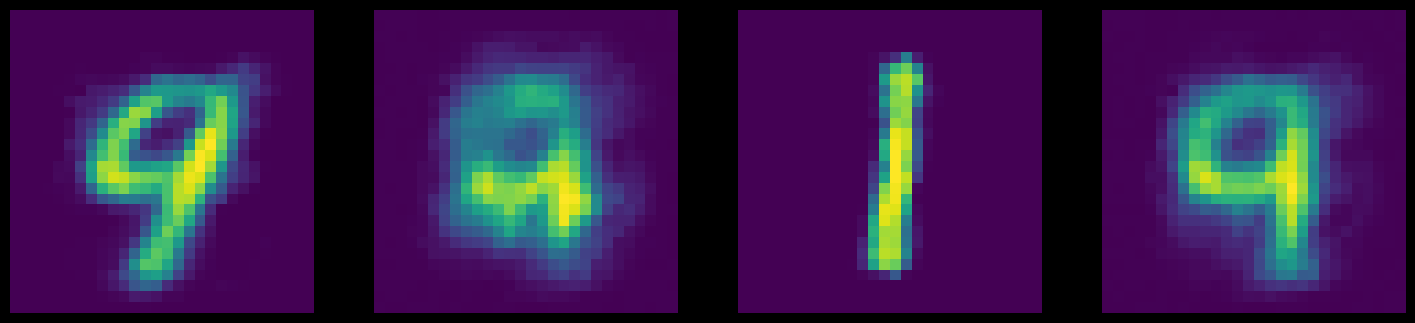

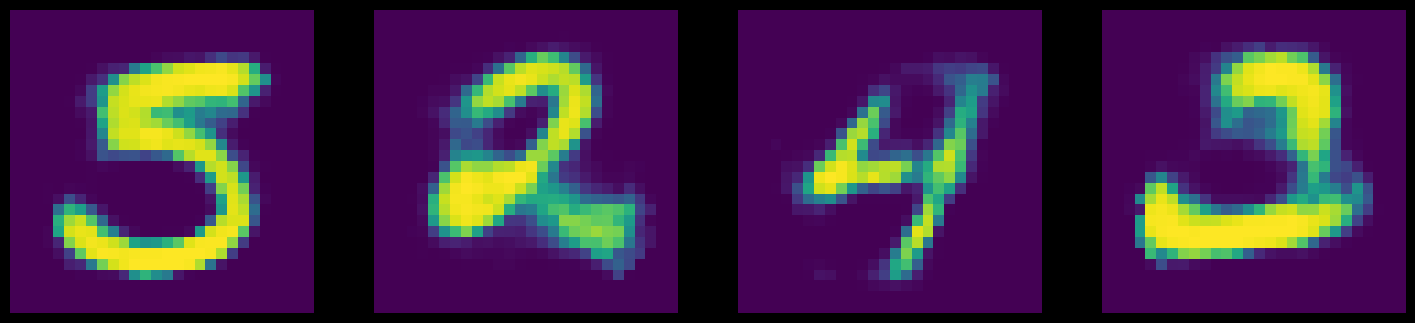

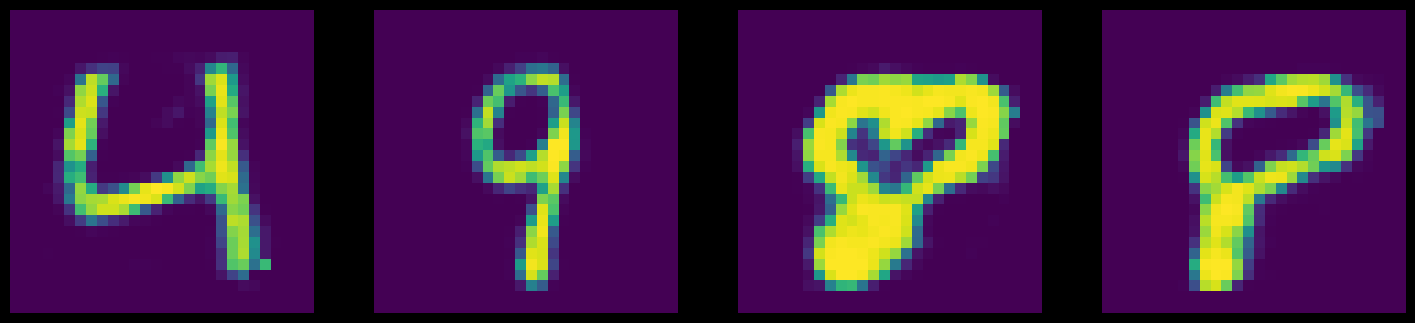

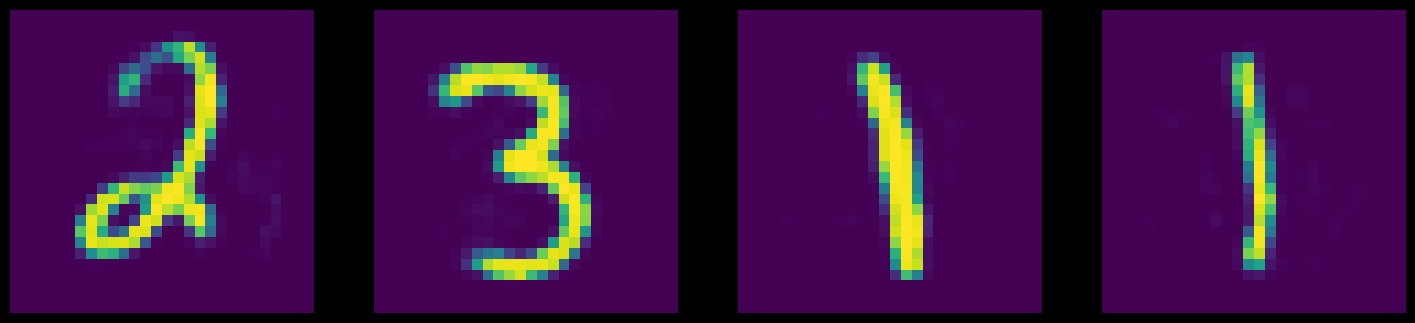

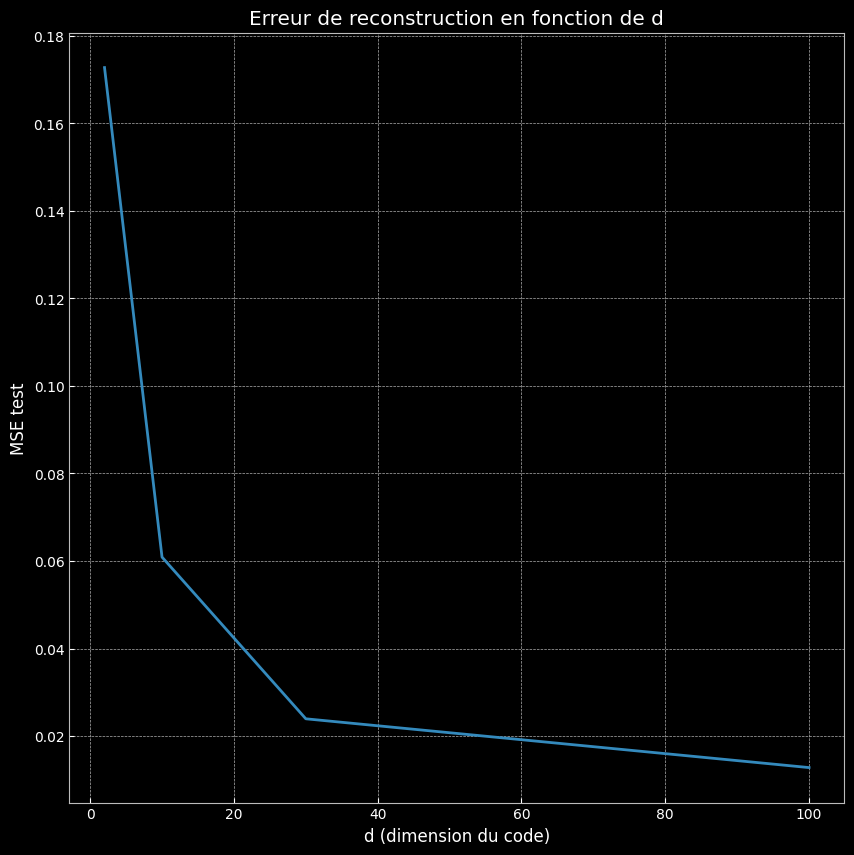

In [43]:
d=30

class Autoencoder_v2(nn.Module):
    def __init__(self):
        super().__init__()
        self.encoder = nn.Sequential(
            nn.Linear(28 * 28, 50 * 50),
            nn.ReLU(),
            nn.Linear(50 * 50, d),

        )
        self.decoder = nn.Sequential(
            nn.Linear(d, 50 * 50),
            nn.ReLU(),
            nn.Linear(50*50, 28 * 28),
            nn.Tanh()
        )

    def forward(self, x):
        x = self.encoder(x)
        x = self.decoder(x)
        return x

liste_mse_model = []

dim_liste = [2, 10, 30, 100]

for d_valeur in dim_liste :

    d = d_valeur
    model_2d = Autoencoder_v2().to(device)
    criterion = nn.MSELoss()
    learning_rate = 1e-3

    optimizer = torch.optim.Adam(
        model_2d.parameters(),
        lr=learning_rate,
    )

    num_epochs = 5
    for epoch in range(num_epochs):
        for data in dataloader:
            img, _ = data
            img = img.to(device)
            img = img.view(img.size(0), -1)

            output = model_2d(img)
            loss = criterion(output, img.data)
            optimizer.zero_grad()
            loss.backward()
            optimizer.step()
        print(f'dim {d} : epoch [{epoch + 1}/{num_epochs}], loss:{loss.item():.4f}')
    display_images(None, output)

    liste_mse_model.append(test_mse(model_2d))

plt.figure()
plt.plot(dim_liste, liste_mse_model)
plt.xlabel("d (dimension du code)")
plt.ylabel("MSE test")
plt.title("Erreur de reconstruction en fonction de d")
plt.show()

On remarque que selon les fonctions d'activation et autres paramètres choisis, les séries d'images diffèrent en netteté : là on a un résultat bien plus propre par exemple ce qui est logique avce 2500 neurones, une activation ReLU en couche cachée et Tahn en sortie. En effet, on avait testé Sigmoid en sortie mais sur des images dans [−1, 1] ça empêche l'apprentissage.
En contrepartie c'est beaucoup plus long et coûteux.

**PART2. Convolutional Neural Networks**

1. Import the libraries and set the parameters

In [44]:
import torch
import torch.nn as nn
import torch.nn.functional as F
import torch.optim as optim
from torchvision import datasets, transforms
import matplotlib.pyplot as plt
import numpy as np


def set_default(figsize=(10, 10), dpi=100):
    plt.style.use(['dark_background', 'bmh'])
    plt.rc('axes', facecolor='k')
    plt.rc('figure', facecolor='k')
    plt.rc('figure', figsize=figsize, dpi=dpi)

set_default()

# function to count number of parameters
def get_n_params(model):
    n = 0
    for p in list(model.parameters()):
        n += p.nelement()
    return n

device = torch.device("cuda:0" if torch.cuda.is_available() else "cpu")

2. Load the Dataset (MNIST) using PyTorch DataLoader utilities and visualize some images :

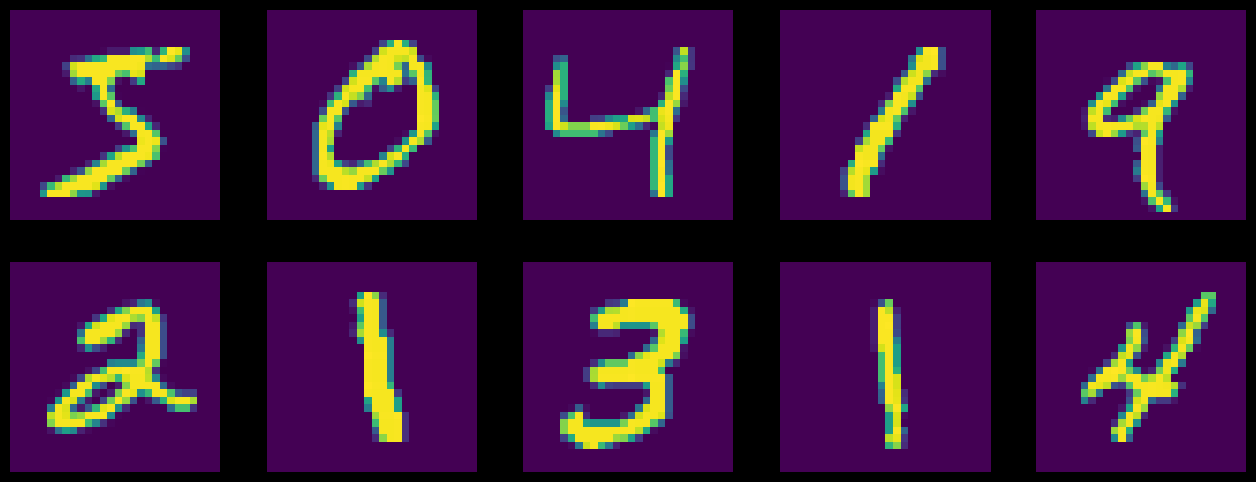

In [45]:
input_size  = 28*28   # images are 28x28 pixels
output_size = 10      # there are 10 classes

train_loader = torch.utils.data.DataLoader(
    datasets.MNIST('../data', train=True, download=True,
                   transform=transforms.Compose([
                       transforms.ToTensor(),
                       transforms.Normalize((0.1307,), (0.3081,))
                   ])),
    batch_size=64, shuffle=True)

test_loader = torch.utils.data.DataLoader(
    datasets.MNIST('../data', train=False, transform=transforms.Compose([
                       transforms.ToTensor(),
                       transforms.Normalize((0.1307,), (0.3081,))
                   ])),
    batch_size=1000, shuffle=True)

plt.figure(figsize=(16, 6))
for i in range(10):
    plt.subplot(2, 5, i + 1)
    image, _ = train_loader.dataset.__getitem__(i)
    plt.imshow(image.squeeze().numpy())
    plt.axis('off');

3. Create the model classes

In [46]:
class FC2Layer(nn.Module):
    def __init__(self, input_size, n_hidden, output_size):
        super(FC2Layer, self).__init__()
        self.input_size = input_size
        self.network = nn.Sequential(
            nn.Linear(input_size, n_hidden),
            nn.ReLU(),
            nn.Linear(n_hidden, n_hidden),
            nn.ReLU(),
            nn.Linear(n_hidden, output_size),
            nn.LogSoftmax(dim=1)
        )

    def forward(self, x):
        x = x.view(-1, self.input_size)
        return self.network(x)

class CNN(nn.Module):
    def __init__(self, input_size, n_feature, output_size):
        super(CNN, self).__init__()
        self.n_feature = n_feature
        self.conv1 = nn.Conv2d(in_channels=1, out_channels=n_feature, kernel_size=5)
        self.conv2 = nn.Conv2d(n_feature, n_feature, kernel_size=5)
        self.fc1 = nn.Linear(n_feature*4*4, 50)
        self.fc2 = nn.Linear(50, 10)

    def forward(self, x, verbose=False):
        if verbose: print(tuple(x.shape))
        x = self.conv1(x)
        if verbose: print(tuple(x.shape))
        x = F.relu(x)
        x = F.max_pool2d(x, kernel_size=2)
        if verbose: print(tuple(x.shape))
        x = self.conv2(x)
        if verbose: print(tuple(x.shape))
        x = F.relu(x)
        x = F.max_pool2d(x, kernel_size=2)
        if verbose: print(tuple(x.shape))
        x = x.view(-1, self.n_feature*4*4)
        x = self.fc1(x)
        x = F.relu(x)
        x = self.fc2(x)
        x = F.log_softmax(x, dim=1)
        return x

4. a. For an input image of size 1×28×28, compute **by hand** the shape of the tensor after each layer of the CNN (conv1, pooling, conv2, pooling). Justify the value `n_feature*4*4` used in `fc1`.

   b. Use the argument `verbose` of `forward` to print these shapes and check your answer.

   c. Compute by hand the number of parameters of the CNN for `n_feature = 6` and of the FC2Layer for `n_hidden = 8`. Check with `get_n_params`.

Réponse 4.a :

D'après le cours (Relationship 6), la taille de sortie d'une convolution ou d'un pooling est :

$$o = \left\lfloor \frac{i + 2p - k}{s} \right\rfloor + 1$$

avec $i$ la taille d'entrée, $k$ la taille du noyau, $p$ le padding et $s$ le stride.

On choisit cette formule car c'est le cas général : elle contient les relations 1, 2 et 5 du cours doc en une formule on a à la fois les convolutions et les poolings du réseau, le pooling fonctionnant comme une convolution.

"self.conv1 = nn.Conv2d(in_channels=1, out_channels=n_feature, kernel_size=5)
self.conv2 = nn.Conv2d(n_feature, n_feature, kernel_size=5)"

Donc `conv1` et `conv2` ont $k=5$, $s=1$ car pas précisé donc valeur par défaut, $p=0$ car pas précisé donc valeur par défaut

"x = F.max_pool2d(x, kernel_size=2)"

Donc `max_pool2d` a $k=2$, $s=2$ car pas précisé donc valeur par défaut pour pooling, $p=0$ car pas précisé donc valeur par défaut

Et en entrée i = 28x28

Donc on a : 
départ : $1 \times 28 \times 28$
- pour `conv1` : $28 - 5 + 1 = 24$ -> n_features $\times 24 \times 24$
- pour `max_pool2d` : $\lfloor (24-2)/2 \rfloor + 1 = 12$ -> n_features $\times 12 \times 12$
- pour `conv2` : $12 - 5 + 1 = 8$ -> n_features $\times 8 \times 8$ 
- pour `max_pool2d` : $\lfloor (8-2)/2 \rfloor + 1 = 4$ -> n_features $\times 4 \times 4$ 

D'où `n_feature*4*4` utilisé dans `fc1`

In [47]:
# Question 4.b)
# on a modif def forward et on l'applique :
m = CNN(input_size, 6, output_size)
formes = m(torch.zeros(1, 1, 28, 28), verbose=True)

(1, 1, 28, 28)
(1, 6, 24, 24)
(1, 6, 12, 12)
(1, 6, 8, 8)
(1, 6, 4, 4)


Quesiton 4.C : Le nombre de paramètres du CNN est donné par la formule qu'on trouve dans le cours : $(C_{in} \cdot k \cdot k + 1) \cdot C_{out}$. Pour une couche linéaire c'est : $(n_{in} + 1) \cdot n_{out}$

Donc pour CNN, n_feature = 6 :

- conv1 : (1·5·5 + 1)·6 = 156 (premiere couche de 1 seul canal d'entrée, n_feature = 6 donc C_out = 6)
- conv2 : (6·5·5 + 1)·6 = 906 (C_in = C_out précédent, n_feature = 6 donc C_out = 6)

self.fc1 = nn.Linear(n_feature* 4 * 4, 50) et self.fc2 = nn.Linear(50, 10) :
- fc1 : (96 + 1)·50 = 4850 (96 = 6x4x4)
- fc2 : (50 + 1)·10 = 510

Total = 6422

Pour FC2Layer n_hidden = 8 
- Linear 1 : (784 + 1)·8 = 6280 (car nn.Linear(input_size = 28x28 = 784, n_hidden))
- Linear 2 : (8 + 1)·8 = 72 (car nn.Linear(n_hidden, n_hidden))
- Linear 3 : (8 + 1)·10 = 90 (car nn.Linear(n_hidden, output_size))

Total = 6442

In [48]:
print(get_n_params(CNN(input_size, 6, output_size)))
print(get_n_params(FC2Layer(input_size, 8, output_size)))

6422
6442


5. Run on a GPU: device string

Switching between CPU and GPU in PyTorch is controlled via a device string, which will seamlessly determine whether GPU is available, falling back to CPU if not:

In [49]:
accuracy_list = []

def train(epoch, model, perm=torch.arange(0, 784).long()):
    model.train()
    for batch_idx, (data, target) in enumerate(train_loader):
        # send to device
        data, target = data.to(device), target.to(device)

        # permute pixels
        data = data.view(-1, 28*28)
        data = data[:, perm]
        data = data.view(-1, 1, 28, 28)

        optimizer.zero_grad()
        output = model(data)
        loss = F.nll_loss(output, target)
        loss.backward()
        optimizer.step()
        if batch_idx % 100 == 0:
            print('Train Epoch: {} [{}/{} ({:.0f}%)]\tLoss: {:.6f}'.format(
                epoch, batch_idx * len(data), len(train_loader.dataset),
                100. * batch_idx / len(train_loader), loss.item()))

def test(model, perm=torch.arange(0, 784).long()):
    model.eval()
    test_loss = 0
    correct = 0
    for data, target in test_loader:
        # send to device
        data, target = data.to(device), target.to(device)

        # permute pixels
        data = data.view(-1, 28*28)
        data = data[:, perm]
        data = data.view(-1, 1, 28, 28)
        output = model(data)
        test_loss += F.nll_loss(output, target, reduction='sum').item() # sum up batch loss
        pred = output.data.max(1, keepdim=True)[1] # get the index of the max log-probability
        correct += pred.eq(target.data.view_as(pred)).cpu().sum().item()

    test_loss /= len(test_loader.dataset)
    accuracy = 100. * correct / len(test_loader.dataset)
    accuracy_list.append(accuracy)
    print('\nTest set: Average loss: {:.4f}, Accuracy: {}/{} ({:.0f}%)\n'.format(
        test_loss, correct, len(test_loader.dataset),
        accuracy))

6. Train a small fully-connected network

In [50]:
n_hidden = 8 # number of hidden units

model_fnn = FC2Layer(input_size, n_hidden, output_size)
model_fnn.to(device)
optimizer = optim.SGD(model_fnn.parameters(), lr=0.01, momentum=0.5)
print('Number of parameters: {}'.format(get_n_params(model_fnn)))

for epoch in range(0, 1):
    train(epoch, model_fnn)
    test(model_fnn)

Number of parameters: 6442
Train Epoch: 0 [0/60000 (0%)]	Loss: 2.344502
Train Epoch: 0 [6400/60000 (11%)]	Loss: 1.730291
Train Epoch: 0 [12800/60000 (21%)]	Loss: 1.115123
Train Epoch: 0 [19200/60000 (32%)]	Loss: 0.655800
Train Epoch: 0 [25600/60000 (43%)]	Loss: 0.637178
Train Epoch: 0 [32000/60000 (53%)]	Loss: 0.485570
Train Epoch: 0 [38400/60000 (64%)]	Loss: 0.480041
Train Epoch: 0 [44800/60000 (75%)]	Loss: 0.533468
Train Epoch: 0 [51200/60000 (85%)]	Loss: 0.500220
Train Epoch: 0 [57600/60000 (96%)]	Loss: 0.478144

Test set: Average loss: 0.4378, Accuracy: 8737/10000 (87%)



7. Train a ConvNet with the same number of parameters

In [51]:
# Training settings
n_features = 6 # number of feature maps

model_cnn = CNN(input_size, n_features, output_size)
model_cnn.to(device)
optimizer = optim.SGD(model_cnn.parameters(), lr=0.01, momentum=0.5)
print('Number of parameters: {}'.format(get_n_params(model_cnn)))

for epoch in range(0, 1):
    train(epoch, model_cnn)
    test(model_cnn)

Number of parameters: 6422
Train Epoch: 0 [0/60000 (0%)]	Loss: 2.295298
Train Epoch: 0 [6400/60000 (11%)]	Loss: 1.704616
Train Epoch: 0 [12800/60000 (21%)]	Loss: 0.440117
Train Epoch: 0 [19200/60000 (32%)]	Loss: 0.365124
Train Epoch: 0 [25600/60000 (43%)]	Loss: 0.230431
Train Epoch: 0 [32000/60000 (53%)]	Loss: 0.340486
Train Epoch: 0 [38400/60000 (64%)]	Loss: 0.341597
Train Epoch: 0 [44800/60000 (75%)]	Loss: 0.379716
Train Epoch: 0 [51200/60000 (85%)]	Loss: 0.394127
Train Epoch: 0 [57600/60000 (96%)]	Loss: 0.275135

Test set: Average loss: 0.1917, Accuracy: 9427/10000 (94%)



8. Permuted pixels. Draw a fixed random permutation of the pixels with `perm = torch.randperm(784)` and display a few permuted images.

   Train a **new** FC2Layer and a **new** CNN (same sizes as above, 1 epoch) on the permuted images, using the argument `perm` of `train` and `test`.

   Compare the 4 accuracies (FC / CNN, original / permuted) in a bar chart. Explain why one model is affected by the permutation and the other is not. Which assumption on images does the CNN rely on?

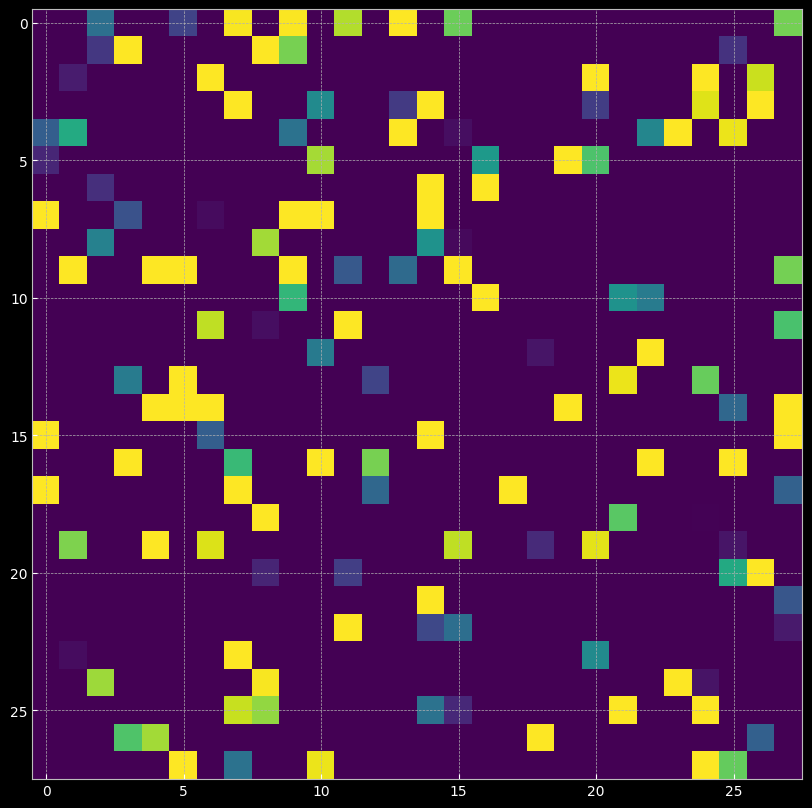

Train Epoch: 0 [0/60000 (0%)]	Loss: 2.354858
Train Epoch: 0 [6400/60000 (11%)]	Loss: 1.915436
Train Epoch: 0 [12800/60000 (21%)]	Loss: 1.229588
Train Epoch: 0 [19200/60000 (32%)]	Loss: 0.906178
Train Epoch: 0 [25600/60000 (43%)]	Loss: 0.593089
Train Epoch: 0 [32000/60000 (53%)]	Loss: 0.368200
Train Epoch: 0 [38400/60000 (64%)]	Loss: 0.563835
Train Epoch: 0 [44800/60000 (75%)]	Loss: 0.727792
Train Epoch: 0 [51200/60000 (85%)]	Loss: 0.421261
Train Epoch: 0 [57600/60000 (96%)]	Loss: 0.342062

Test set: Average loss: 0.3954, Accuracy: 8819/10000 (88%)

Train Epoch: 0 [0/60000 (0%)]	Loss: 2.309680
Train Epoch: 0 [6400/60000 (11%)]	Loss: 1.970504
Train Epoch: 0 [12800/60000 (21%)]	Loss: 1.143342
Train Epoch: 0 [19200/60000 (32%)]	Loss: 0.923496
Train Epoch: 0 [25600/60000 (43%)]	Loss: 0.892200
Train Epoch: 0 [32000/60000 (53%)]	Loss: 0.649374
Train Epoch: 0 [38400/60000 (64%)]	Loss: 0.900698
Train Epoch: 0 [44800/60000 (75%)]	Loss: 0.763357
Train Epoch: 0 [51200/60000 (85%)]	Loss: 0.547823
T

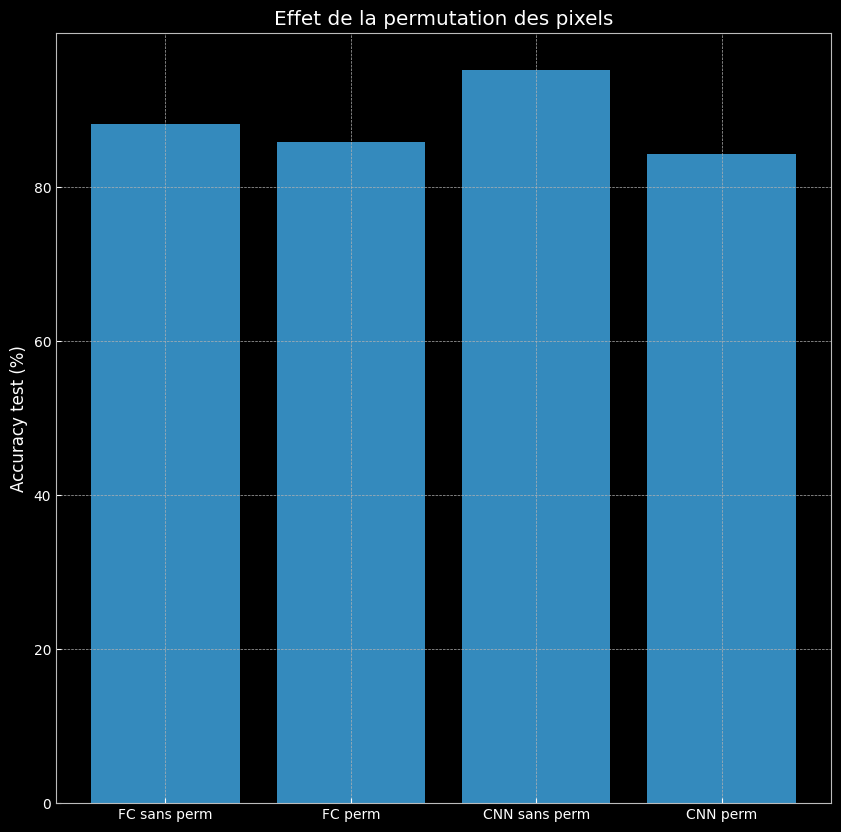

[88.19, 85.85, 95.19, 84.23]


In [56]:
perm = torch.randperm(784)
i = 5
for data, target in test_loader:
  # send to device
  data, target = data.to(device), target.to(device)

  # permute pixels
  data = data.view(-1, 28*28)
  data = data[:, perm]
  data = data.view(-1, 1, 28, 28)
  i -= 1 
  if i <= 0 :
    break
plt.figure()
plt.imshow(data[1].view(28, 28).cpu()) # d'apres l'ia
plt.show()

accuracy_list = [] #la fct train & test ajoute dans cette liste , mais elle des truc à l'interieur donc je l'init ici comme ça elle est vide hihihi
#FC2layer - Sans perm
model = FC2Layer(input_size, n_hidden, output_size).to(device)
optimizer = optim.SGD(model.parameters(), lr=0.01, momentum=0.5)
train(0, model)
test(model)

#FC2layer - Avec perm
model = FC2Layer(input_size, n_hidden, output_size).to(device)
optimizer = optim.SGD(model.parameters(), lr=0.01, momentum=0.5)
train(0, model, perm)
test(model, perm)

#CNN - Sans perm
model = CNN(input_size, n_features, output_size).to(device)
optimizer = optim.SGD(model.parameters(), lr=0.01, momentum=0.5)
train(0, model)
test(model)

#CNN - Avec perm
model = CNN(input_size, n_features, output_size).to(device)
optimizer = optim.SGD(model.parameters(), lr=0.01, momentum=0.5)
train(0, model,perm)
test(model,perm)

noms = ['FC sans perm', 'FC perm', 'CNN sans perm', 'CNN perm']
plt.figure()
plt.bar(noms, accuracy_list)
plt.ylabel("Accuracy test (%)")
plt.title("Effet de la permutation des pixels")
plt.show()
print(accuracy_list)

- Le FC n’est pas affecté par la permutation : il traite chaque pixel comme une entrée indépendante donc réordonner les pixels revient juste à réordonner les colonnes de sa première matrice de poids. Son accuracy reste à peu près la même ( 88.19% -> 85.85%)

- Le CNN est affecté : il passe de 95.19% à 84.23% car ses filtres regardent des groupes de pixels voisins et la permutation détruit ce voisinage.

Le CNN repose donc sur l’hypothèse de localité spatiale : les pixels proches sont corrélés et forment des motifs locaux (traits, bords), que l’on peut détecter partout dans l’image grâce au partage des poids.

9. Compute and display the confusion matrix (10×10) of the CNN trained on the original images, on the test set. Which digits are most often confused? Display 8 misclassified test images with their true and predicted labels.

In [66]:
from sklearn.metrics import confusion_matrix
model_cnn.eval()

vrai_label = []
predit_label = []

for data, target in test_loader:

    data, target = data.to(device), target.to(device)

    vrai_label.extend(target.cpu().numpy()) 

    output = model_cnn(data)

    predictions = torch.argmax(output, dim=1) # Argmax : Récupère la classe prédite.

    predit_label.extend(predictions.cpu().numpy()) # On recup de CPU + Convertit le tenseur PyTorch en tableau NumPy.

#- extend() ajoute les éléments du tableau individuellement dans la liste.

matrice = confusion_matrix(vrai_label, predit_label)
#Ligne : Vrai | Colonne : Predit
print(matrice)

dico_confusion_occ = {}

for i in range(10):
    dico_confusion_occ[i] = 0

    for j in range(10):
        if i != j:
            dico_confusion_occ[i] += matrice[i, j]
print(dico_confusion_occ)

print(f"La valeur la plus confondue est : {max(dico_confusion_occ, key=dico_confusion_occ.get)}")

[[ 964    0    1    0    0    7    3    2    3    0]
 [   0 1119    5    2    0    3    2    0    4    0]
 [   6    1  973   17   11    5    3    9    7    0]
 [   3    0   16  951    0   23    0    8    6    3]
 [   1    1    3    0  954    0    3    1    4   15]
 [   4    1    0   14    2  863    4    1    2    1]
 [  18    2    2    0   27   29  875    0    5    0]
 [   2    4   30    9    2    1    0  968    4    8]
 [   8    2    2   21   10   26    6   12  881    6]
 [   8    6    0   13   54   21    0   21    7  879]]
{0: 16, 1: 16, 2: 59, 3: 59, 4: 28, 5: 29, 6: 83, 7: 60, 8: 93, 9: 130}
La valeur la plus confondue est : 9


In [68]:
# Version on a aussi calculé les occurences des confusions d'un chiffre avec une valeur précise :
from sklearn.metrics import confusion_matrix

model_cnn.eval()

vrai_label = []
predit_label = []

for data, target in test_loader:

    data, target = data.to(device), target.to(device)

    vrai_label.extend(target.cpu().numpy()) 

    output = model_cnn(data)

    predictions = torch.argmax(output, dim=1) #Argmax : Récupère la classe prédite.

    predit_label.extend(predictions.cpu().numpy()) #On recup de CPU + Convertit le tenseur PyTorch en tableau NumPy.

#- extend() ajoute les éléments du tableau individuellement dans la liste.

matrice = confusion_matrix(vrai_label, predit_label)
#Ligne : Vrai | Colonne : Predit
print(matrice)

for i in range(10):
    for j in range(10):
        if i != j and matrice[i, j] > 25:
            print(i, "confondu avec", j, ":", matrice[i, j])

[[ 964    0    1    0    0    7    3    2    3    0]
 [   0 1119    5    2    0    3    2    0    4    0]
 [   6    1  973   17   11    5    3    9    7    0]
 [   3    0   16  951    0   23    0    8    6    3]
 [   1    1    3    0  954    0    3    1    4   15]
 [   4    1    0   14    2  863    4    1    2    1]
 [  18    2    2    0   27   29  875    0    5    0]
 [   2    4   30    9    2    1    0  968    4    8]
 [   8    2    2   21   10   26    6   12  881    6]
 [   8    6    0   13   54   21    0   21    7  879]]
6 confondu avec 4 : 27
6 confondu avec 5 : 29
7 confondu avec 2 : 30
8 confondu avec 5 : 26
9 confondu avec 4 : 54


10. Change the parameters of the models (number of feature maps, number of hidden units, number of epochs, learning rate)

In [69]:
class CNN_v2(nn.Module):
    def __init__(self, input_size, n_feature, output_size):
        super(CNN_v2, self).__init__()
        self.n_feature = n_feature
        self.conv1 = nn.Conv2d(in_channels=1, out_channels=n_feature, kernel_size=5)
        self.conv2 = nn.Conv2d(n_feature, n_feature, kernel_size=5)
        self.fc1 = nn.Linear(n_feature*4*4, 50)
        self.fc2 = nn.Linear(50, 80)
        self.fc3 = nn.Linear(80, 110)
        self.fc4 = nn.Linear(110, 10)

    def forward(self, x, verbose=False):
        x = self.conv1(x)
        x = F.relu(x)
        x = F.max_pool2d(x, kernel_size=2)
        x = self.conv2(x)
        x = F.relu(x)
        x = F.max_pool2d(x, kernel_size=2)
        x = x.view(-1, self.n_feature*4*4)
        x = self.fc1(x)
        x = F.relu(x)
        x = self.fc2(x)
        x = F.relu(x)
        x = self.fc3(x)
        x = F.relu(x)
        x = self.fc4(x)
        x = F.log_softmax(x, dim=1)
        return x

n_features = 16 # number of feature maps

model_cnn_v2 = CNN_v2(input_size, n_features, output_size)
model_cnn_v2.to(device)
optimizer = optim.SGD(model_cnn_v2.parameters(), lr=0.0084, momentum=0.5)
print('Number of parameters: {}'.format(get_n_params(model_cnn_v2)))

for epoch in range(0, 10):
    train(epoch, model_cnn_v2)
    test(model_cnn_v2)


model_cnn_v2.eval()

vrai_label = []
predit_label = []

for data, target in test_loader:

    data, target = data.to(device), target.to(device)

    vrai_label.extend(target.cpu().numpy()) 

    output = model_cnn_v2(data)

    predictions = torch.argmax(output, dim=1) #Argmax : Récupère la classe prédite.

    predit_label.extend(predictions.cpu().numpy())
matrice = confusion_matrix(vrai_label, predit_label)
#Ligne : Vrai | Colonne : Predit
print(matrice)
for i in range(10):
    for j in range(10):
        if i != j and matrice[i, j] > 8:
            print(i, "confondu avec", j, ":", matrice[i, j])

Number of parameters: 33782
Train Epoch: 0 [0/60000 (0%)]	Loss: 2.303453
Train Epoch: 0 [6400/60000 (11%)]	Loss: 2.286277
Train Epoch: 0 [12800/60000 (21%)]	Loss: 2.282961
Train Epoch: 0 [19200/60000 (32%)]	Loss: 2.268655
Train Epoch: 0 [25600/60000 (43%)]	Loss: 1.995101
Train Epoch: 0 [32000/60000 (53%)]	Loss: 0.734331
Train Epoch: 0 [38400/60000 (64%)]	Loss: 0.535562
Train Epoch: 0 [44800/60000 (75%)]	Loss: 0.519932
Train Epoch: 0 [51200/60000 (85%)]	Loss: 0.233355
Train Epoch: 0 [57600/60000 (96%)]	Loss: 0.264694

Test set: Average loss: 0.2408, Accuracy: 9280/10000 (93%)

Train Epoch: 1 [0/60000 (0%)]	Loss: 0.184866
Train Epoch: 1 [6400/60000 (11%)]	Loss: 0.265412
Train Epoch: 1 [12800/60000 (21%)]	Loss: 0.256573
Train Epoch: 1 [19200/60000 (32%)]	Loss: 0.210808
Train Epoch: 1 [25600/60000 (43%)]	Loss: 0.146653
Train Epoch: 1 [32000/60000 (53%)]	Loss: 0.116767
Train Epoch: 1 [38400/60000 (64%)]	Loss: 0.239969
Train Epoch: 1 [44800/60000 (75%)]	Loss: 0.133509
Train Epoch: 1 [51200/6

11. Analyze the results and the impact of these parameters, in particular the trade-off between number of parameters and accuracy.

L'augmentation de n_features = 16, l'ajout de couches cachées supplémentaires (fc2, fc3) et l'ajustement du taux d'apprentissage permettent de faire passer l'accuracy à 99 %, ce qui montre un vrai compromis où l'augmentation de la complexité et du nombre de paramètres du modèle améliore réellement sa capacité de généralisation et réduit les confusions par rapport au modèle initial